In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('merged_data.xlsx')
df["Donor"] = df["Donor"].astype("string").str.strip()
df["Treg"] = pd.to_numeric(df["Treg"].astype(
    "string").str.strip(), errors="coerce")

In [ ]:
# from src.pipeline import summarize_categorical_data, plot_categorical_summary

# categorical_summary = summarize_categorical_data(df)
# plot_categorical_summary(categorical_summary, variables=[
#                          "Sex", "Ethnicity", "Tissue"])

In [3]:
from src.pipeline import analyze_tissue_demographics, analyze_tissue_demographic_group_combinations

df = df.rename(columns={
    "Ethnicity:": "Ethnicity",
    "Age (yr):": "Age",
    "BMI (kg/m^2):": "BMI",
    "Sex:": "Sex",
})

exclude_cols = {"Donor", "Ethnicity", "Age", "BMI", "Sex", "Tissue"}
subsets_to_test = [col for col in df.columns if col not in exclude_cols]

summary_stats_df = analyze_tissue_demographics(
    df, subset_columns=subsets_to_test
)
group_comparison_stats_df = analyze_tissue_demographic_group_combinations(
    df, subset_columns=subsets_to_test
)

2026-11-13 14:54:07,260 - INFO - Processing Target Subset: CD4 CD45RA+CCR7+
2026-11-13 14:54:07,276 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue SPL: [(1532, 'Alaska Native')]
2026-11-13 14:54:07,283 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue TONS: [(3, 'Asian')]
2026-11-13 14:54:07,284 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue LLN: [(1536, 'Alaska Native')]
2026-11-13 14:54:07,291 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue MLN: [(1535, 'Alaska Native')]
2026-11-13 14:54:07,299 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue ILN: [(6, 'Asian')]
2026-11-13 14:54:07,304 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue SG: [(7, 'Asian')]
2026-11-13 14:5

In [4]:
significant_hits = summary_stats_df[summary_stats_df["Is_Significant_FDR"]]
significant_hits = significant_hits[~significant_hits["Demographic_Variable"].isin([
                                                                                   "Age", "BMI"])]
significant_hits[["Subset", "Tissue",
                  "Demographic_Variable", "Coefficient", "p_value", "p_value_FDR"]]

,Subset,Tissue,Demographic_Variable,Coefficient,p_value,p_value_FDR
37,CD4 CD45RA+CCR7+,LNG,Ethnicity: Black or African American,-10.399033,0.000118,0.006515
206,CD4 CD45RA+CCR7-,HLN,Sex: FEMALE,7.306294,0.000799,0.031152
1282,CD8 CD103+CD69+,SPL,Ethnicity: Hispanic/Latino,14.260375,0.001271,0.041073


In [ ]:
# from src.pipeline import regression_bmi

# regression_bmi(df, subset='Treg', tissue='SPL')

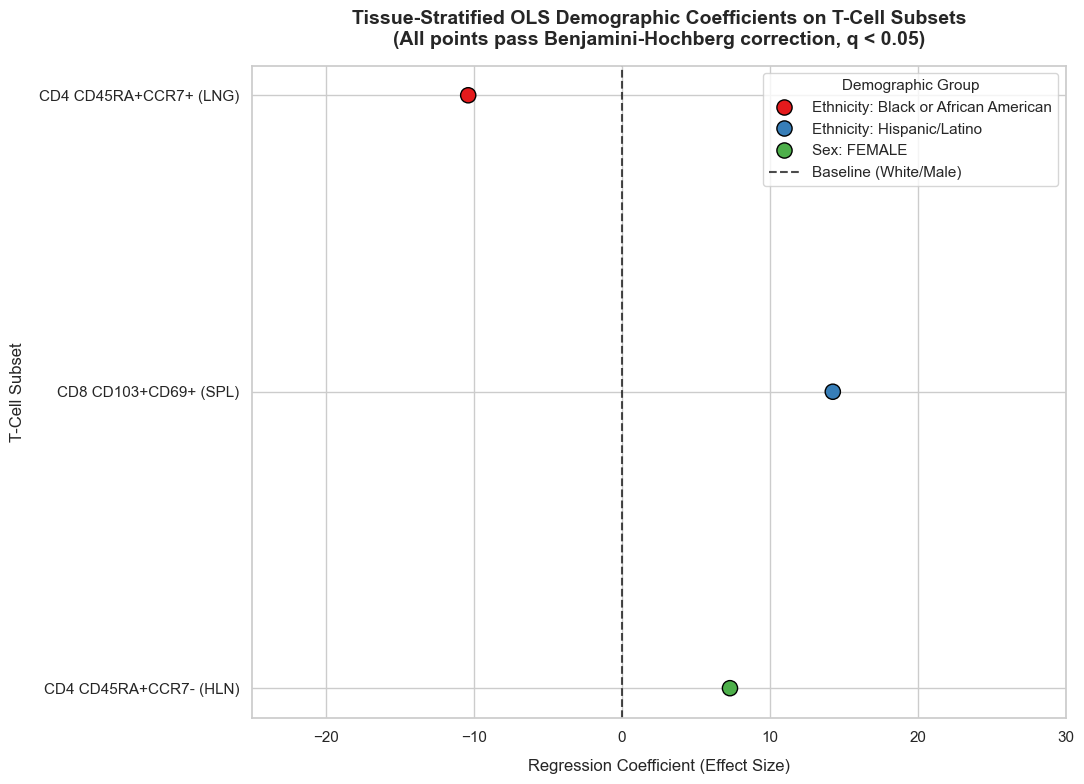

In [5]:
from src.pipeline import ols_summary
ols_summary(significant_hits)

In [ ]:
# from src.pipeline import visualize_ols_vs_mann_whitney_colored
# visualize_ols_vs_mann_whitney_colored(
#     df=df,
#     population_name="CD8 CD45RA-CCR7- CD69-CD103-",
#     tissue="SPL",
#     target_variable="C(Sex, Treatment(reference='MALE'))[T.FEMALE]",
#     color_by="Ethnicity"
# )

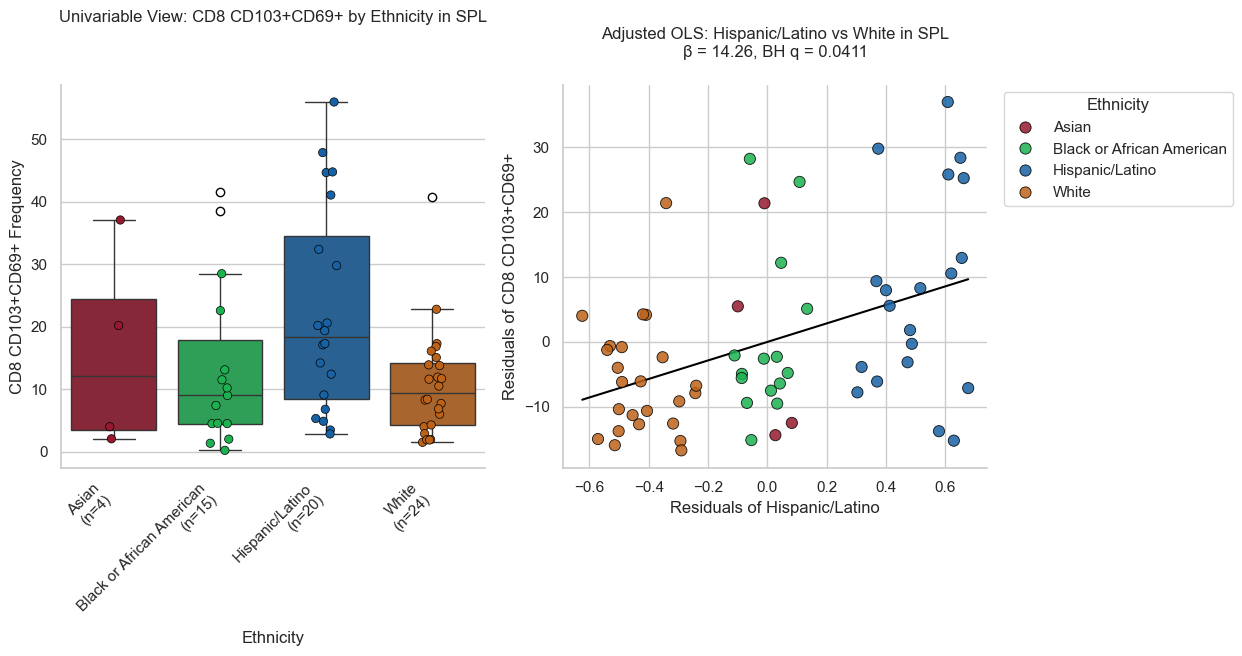

In [7]:
from src.pipeline import visualize_ols_vs_mann_whitney
target_variable = "C(Ethnicity, Treatment(reference='White'))[T.Hispanic/Latino]"
target_q = summary_stats_df.loc[
    (summary_stats_df["Subset"] == "CD8 CD103+CD69+") &
    (summary_stats_df["Tissue"] == "SPL") &
    (summary_stats_df["Demographic_Variable"]
     == "Ethnicity: Hispanic/Latino"),
    "p_value_FDR"
]
visualize_ols_vs_mann_whitney(
    df=df,
    population_name="CD8 CD103+CD69+",
    tissue="SPL",
    target_variable=target_variable,
    adjusted_p_value=target_q.iloc[0] if not target_q.empty else None,
)

/Users/derekmartinez/Documents/Farber Lab/Donor Integrative Study/Donor Integrative Analysis/src/pipeline.py:1440: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([


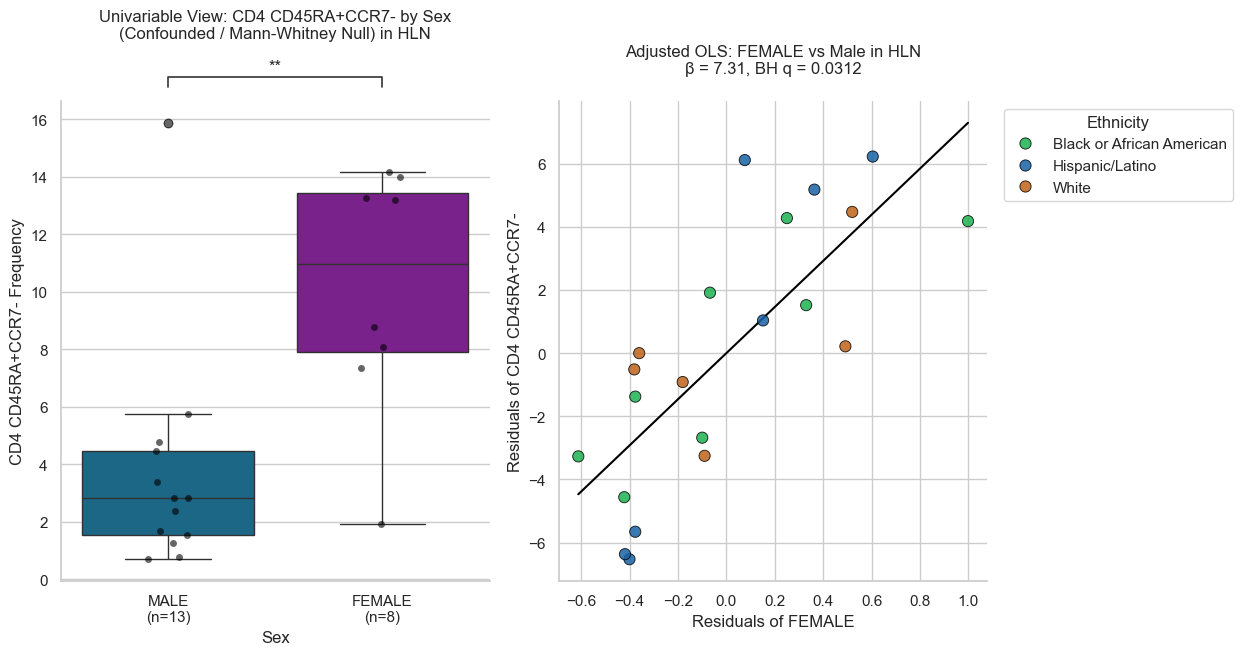

In [6]:
from src.pipeline import visualize_ols_vs_mann_whitney

target_variable = "C(Sex, Treatment(reference='MALE'))[T.FEMALE]"

target_q = summary_stats_df.loc[
    (summary_stats_df["Subset"] == "CD4 CD45RA+CCR7-") &
    (summary_stats_df["Tissue"] == "HLN") &
    (summary_stats_df["Demographic_Variable"] == "Sex: FEMALE"),
    "p_value_FDR"
]

visualize_ols_vs_mann_whitney(
    df=df,
    population_name="CD4 CD45RA+CCR7-",
    tissue="HLN",
    target_variable=target_variable,
    adjusted_p_value=target_q.iloc[0] if not target_q.empty else None,
)

2026-11-11 13:16:52,696 - INFO - Outlier donors for CD8 CD103+CD69+ in tissue SPL: D0491, D0545, D0572


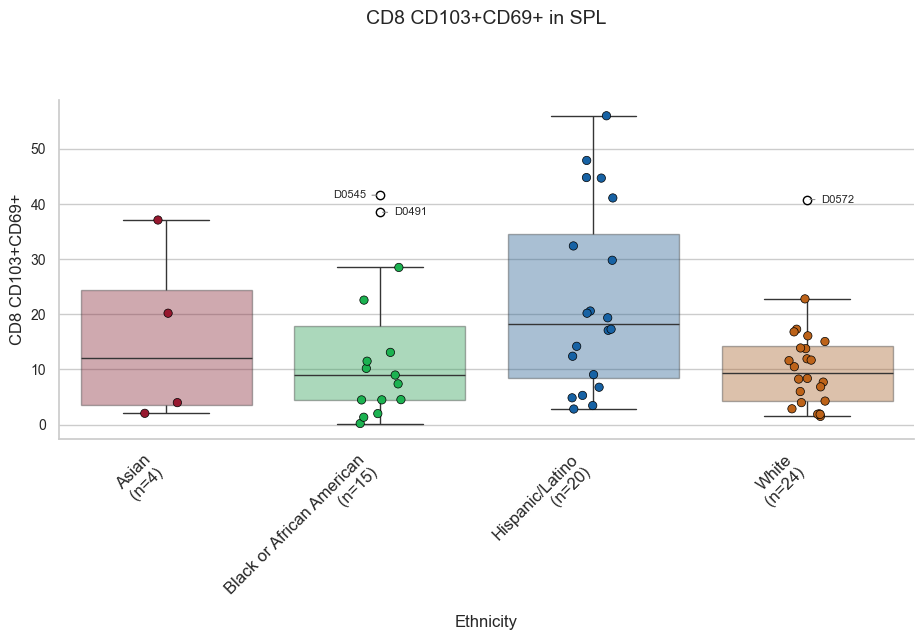

In [8]:
from src.pipeline import stat_boxplot
stat_boxplot(df, population_name='CD8 CD103+CD69+',
             tissue='SPL')

2026-11-11 13:31:14,440 - INFO - Outlier donors for CD4 CD45RA+CCR7- in tissue HLN: D0353


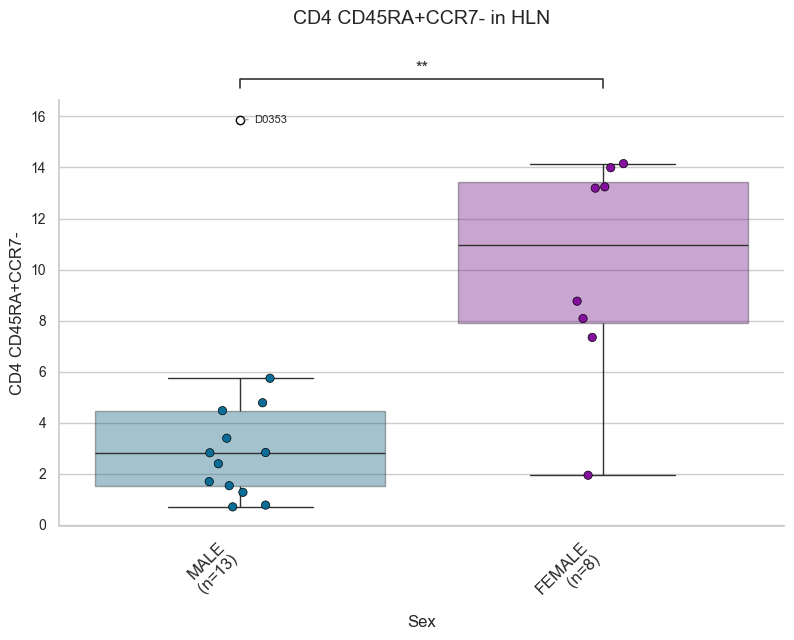

In [9]:
from src.pipeline import sex_boxplot
sex_boxplot(df, population_name="CD4 CD45RA+CCR7-", tissue="HLN")

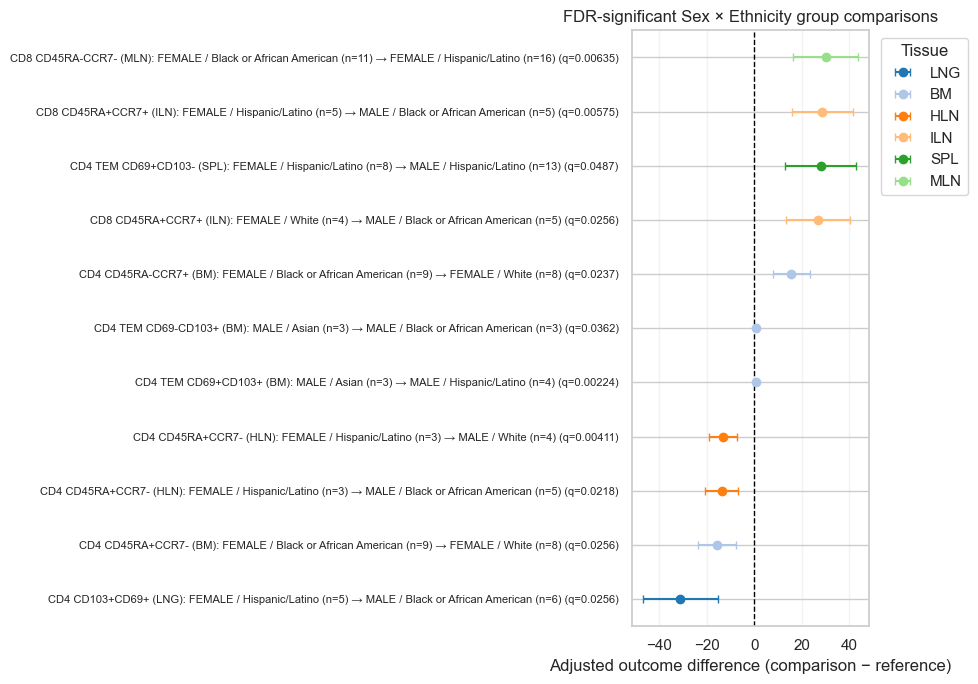

In [6]:
from src.pipeline import plot_group_comparison_summary
plot_group_comparison_summary(group_comparison_stats_df)

2026-11-10 23:15:31,468 - INFO - Excluding ethnicity groups with fewer than 2 observations for CD8 CD45RA-CCR7- in tissue MLN: ['Asian', 'Alaska Native']
2026-11-10 23:15:31,473 - INFO - Outlier donors for CD8 CD45RA-CCR7- in tissue MLN: D0147


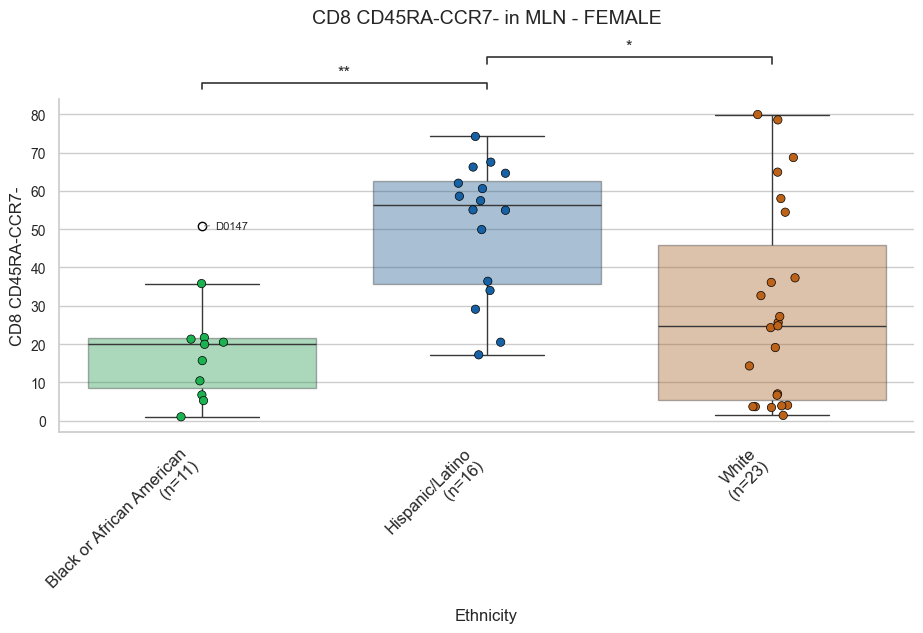

In [19]:
from src.pipeline import stat_boxplot
stat_boxplot(df, population_name='CD8 CD45RA-CCR7-',
             tissue='MLN', sex="FEMALE")

2026-11-10 23:15:33,194 - INFO - Outlier donors for CD4 TEM CD69+CD103- in tissue SPL: D0452, D0546, D0555, D0573


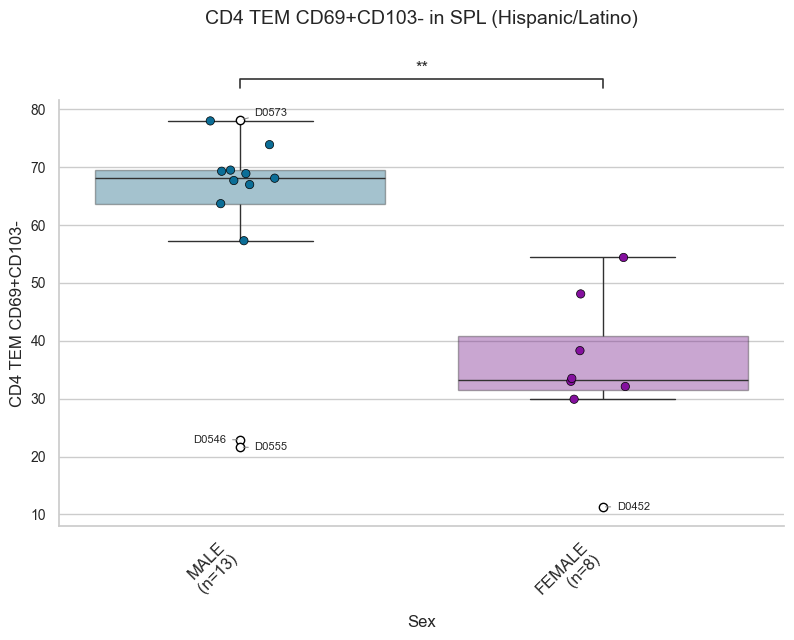

In [20]:
from src.pipeline import sex_boxplot
sex_boxplot(df, population_name="CD4 TEM CD69+CD103-", tissue="SPL",
            ethnicity="Hispanic/Latino")

In [ ]:
# from src.pipeline import sex_ethnicity_boxplot

# sex_ethnicity_boxplot(
#     df,
#     population_name="CD8 CD45RA+CCR7+",
#     tissue="ILN",
#     groups=[
#         ("FEMALE", "Hispanic/Latino"),
#         ("MALE", "Black or African American"),
#     ],
# )

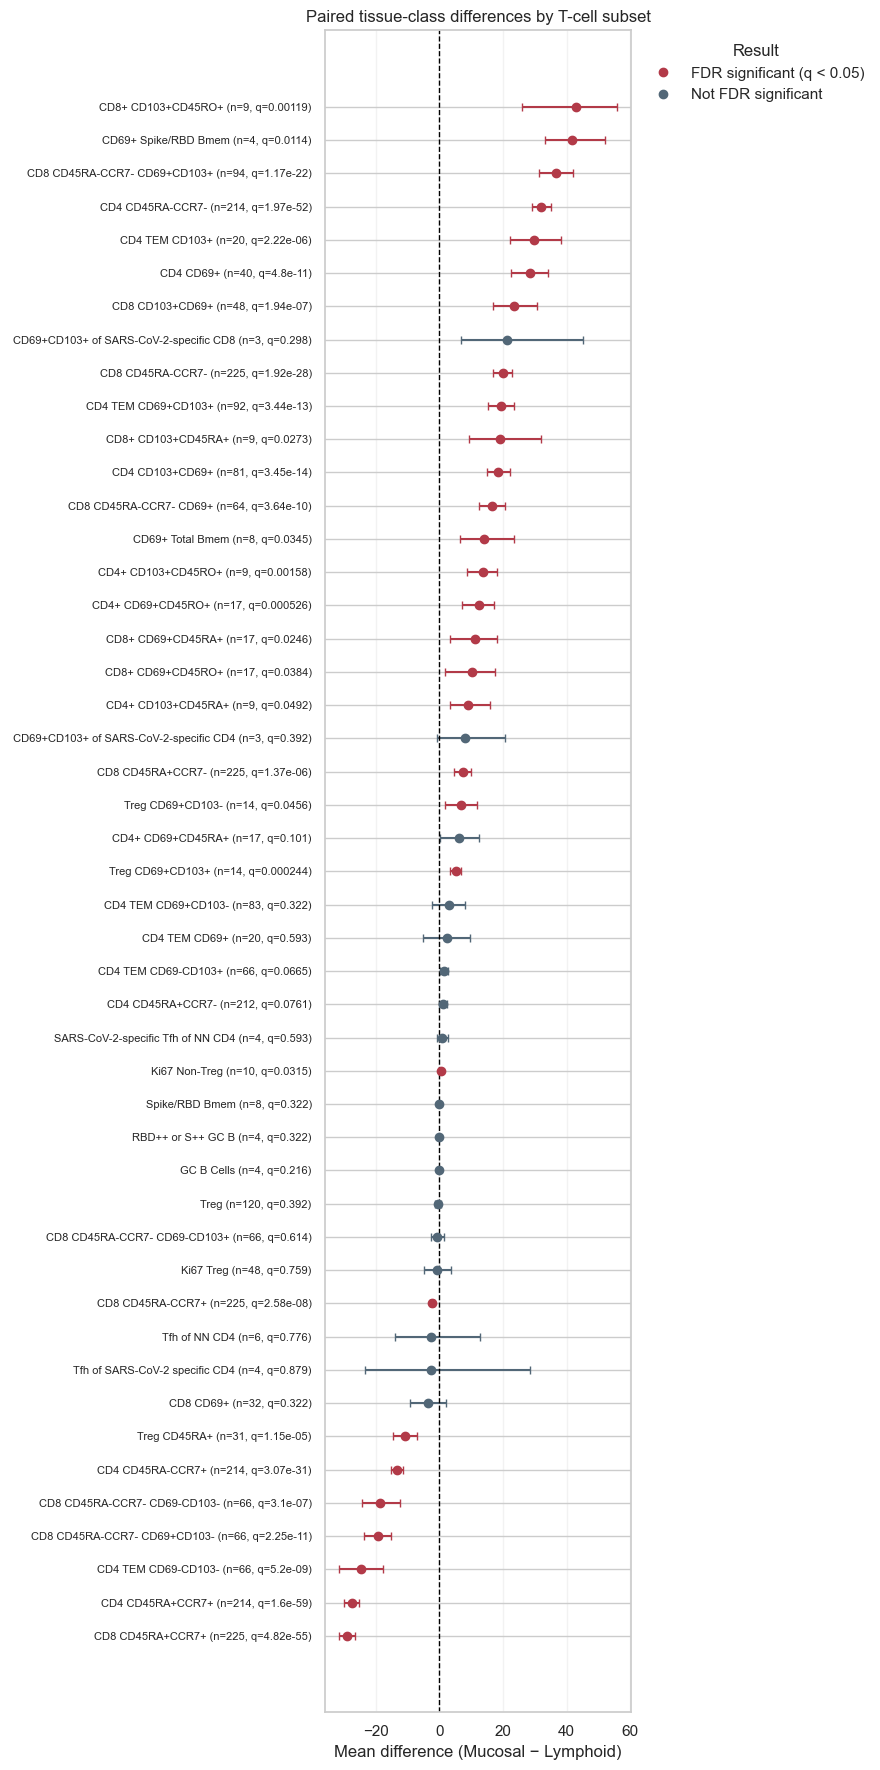

In [7]:
from src.pipeline import analyze_paired_tissue_classes, plot_paired_tissue_class_summary

tissue_class_map = {
    tissue: "Mucosal"
    for tissue in ['JEJ', 'ILE', 'JEL', 'JLP', 'LNG', 'COL']
}
tissue_class_map.update({
    tissue: "Lymphoid"
    for tissue in ['BM', 'HLN', 'LLN', 'MLN', 'SPL', 'TLN', 'ILN']
})

paired_results = analyze_paired_tissue_classes(
    df,
    subsets_to_test,
    tissue_class_map,
    class_a="Mucosal",
    class_b="Lymphoid",
)
plot_paired_tissue_class_summary(paired_results)

In [20]:
from src.pipeline import (
    analyze_paired_tissue_demographics,
    plot_paired_tissue_demographic_summary,
)
import importlib
import src.pipeline
importlib.reload(src.pipeline)


paired_demographic_results = analyze_paired_tissue_demographics(
    df,
    subsets_to_test,
    tissue_class_map,
    class_a="Mucosal",
    class_b="Lymphoid",
)

paired_demographic_results.sort_values("p_value_FDR").head(25)

plot_paired_tissue_demographic_summary(
    paired_demographic_results,
    demographic_variable="Ethnicity: White",
)

2026-11-13 15:09:09,299 - INFO - Skipping demographic model for Treg CD69+CD103+: 13 complete paired donors
2026-11-13 15:09:09,303 - INFO - Skipping demographic model for Treg CD69+CD103-: 13 complete paired donors
2026-11-13 15:09:09,307 - INFO - Skipping demographic model for Ki67 Non-Treg: 8 complete paired donors
2026-11-13 15:09:09,394 - INFO - Skipping demographic model for CD4+ CD69+CD45RA+: 13 complete paired donors
2026-11-13 15:09:09,397 - INFO - Skipping demographic model for CD4+ CD69+CD45RO+: 13 complete paired donors
2026-11-13 15:09:09,401 - INFO - Skipping demographic model for CD8+ CD69+CD45RA+: 13 complete paired donors
2026-11-13 15:09:09,405 - INFO - Skipping demographic model for CD8+ CD69+CD45RO+: 13 complete paired donors
2026-11-13 15:09:09,409 - INFO - Skipping demographic model for CD4+ CD103+CD45RA+: 8 complete paired donors
2026-11-13 15:09:09,413 - INFO - Skipping demographic model for CD4+ CD103+CD45RO+: 8 complete paired donors
2026-11-13 15:09:09,417 - 